In [420]:
import pandas as pd
import re
import os #pour naviguer dans les dossiers
from io import StringIO
import s3fs #pour connecter au bucket

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [421]:


# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})

BUCKET_OUT = "aluneau"

last_file="anonymous_answer_2026-07-24.csv"


In [422]:
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "r") as file_in:
    df0 = pd.read_csv(file_in, sep =",")


In [423]:
df_col = pd.read_csv("../le_questionnaire/dico_variable.csv", sep = ",")

# Profil disciplinaire

In [424]:
def split_multiple_choices(data, column, index, sep = '|'):
    """
    split and explode column with multiple value

    data = a panda dataframe
    column = name of column which we want to split.
    index = column corresponding to id of rows
    sep = by default '|'. Character use to separate values.
    """
    df_split = data.copy()
    df_split[column] = df_split[column].str.split(sep)
    df_explode = df_split.explode(column)
    gb_data = df_explode.groupby([column]).agg(nb = (index, "size")).reset_index()
    gb_data["total"] = data[index].nunique()
    gb_data["freq"] = gb_data.nb/gb_data.total*100
    gb_data["total_freq"] = gb_data.total/gb_data.total*100

    return gb_data, df_explode

In [425]:
gb_data, df_exp = split_multiple_choices(df0, column='q10_type_data', index = "q45_clé", sep = ';')
gb_data1, df_exp1 = split_multiple_choices(df0, column='q5_logiciel_traitement_rec', index = "q45_clé", sep = '|')


In [426]:
df_rf = df_exp[["q45_clé", 'q10_type_data']].copy()
df_rf.loc[df_rf.q10_type_data.isna(), "q10_type_data"] = "Aucune donnée"
df_rf.loc[df_rf.q10_type_data=="Aucune donnée"]
df_rf["value"] = "Oui"
df_rf["question"] = 'q10_type_data'

df_rf["nb"] = df_rf.groupby(["q10_type_data"])["q45_clé"].transform("count")
df_rf2 = df_rf.loc[df_rf.nb>5]


In [427]:
df_d = df_exp1[["q45_clé", 'q5_logiciel_traitement_rec']].copy()
df_d.loc[df_d.q5_logiciel_traitement_rec.isna(), "q5_logiciel_traitement_rec"] = "Aucun logiciel"
df_d.loc[df_d.q5_logiciel_traitement_rec=="Aucun logiciel"]
df_d["value"] = "Oui"
df_d["question"] = 'q5_logiciel_traitement_rec'
df_d["nb"] = df_d.groupby(["q5_logiciel_traitement_rec"])["q45_clé"].transform("count")
df_d2 = df_d.loc[df_d.nb>5]
df_d2


,q45_clé,q5_logiciel_traitement_rec,value,question,nb
0,PS8W-TJ9P,Aucun logiciel,Oui,q5_logiciel_traitement_rec,25
1,GNEG-5QXQ,Aucun logiciel,Oui,q5_logiciel_traitement_rec,25
2,FCCB-GMYA,excel,Oui,q5_logiciel_traitement_rec,79
3,CV3G-95CT,r,Oui,q5_logiciel_traitement_rec,38
4,9EAP-NB4B,excel,Oui,q5_logiciel_traitement_rec,79
...,...,...,...,...,...
116,HRZG-6JGE,r,Oui,q5_logiciel_traitement_rec,38
116,HRZG-6JGE,excel,Oui,q5_logiciel_traitement_rec,79
117,32TW-JLY5,python,Oui,q5_logiciel_traitement_rec,23
117,32TW-JLY5,excel,Oui,q5_logiciel_traitement_rec,79


In [428]:
df_d2.loc[df_d2.q5_logiciel_traitement_rec=="nvivo"]

,q45_clé,q5_logiciel_traitement_rec,value,question,nb
17,RXPG-46ZW,nvivo,Oui,q5_logiciel_traitement_rec,6
46,N99W-FKD9,nvivo,Oui,q5_logiciel_traitement_rec,6
47,VR4Q-ZFTH,nvivo,Oui,q5_logiciel_traitement_rec,6
49,CALH-8CSE,nvivo,Oui,q5_logiciel_traitement_rec,6
74,GLRV-TMM9,nvivo,Oui,q5_logiciel_traitement_rec,6
111,Q934-QKAW,nvivo,Oui,q5_logiciel_traitement_rec,6


In [429]:
df_df=pd.concat([df_d2.rename(columns={"q5_logiciel_traitement_rec":"variable"}), df_rf2.rename(columns={"q10_type_data":"variable"},)])
#df_df = df_df.loc[~df_df.variable.isna()]


In [313]:
def create_term_term_matrix(data, what, list_columns, value, fill_value=0):
    table = pd.pivot_table(data, 
                           values=value, index=what, columns=list_columns, aggfunc=np.sum, fill_value=fill_value)
    
    #term_term = np.dot(table, table.T) # multiplication de la transposé de
    return table

In [430]:
table = create_term_term_matrix(data = df_df,  what ="q45_clé", list_columns=["variable"], value="value", fill_value="Non")
table

/tmp/ipykernel_2651/4196202599.py:2: FutureWarning: The provided callable <function sum at 0x7f50682bb7e0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,


variable,Aucun logiciel,Données d'enquête,Données d'entretien,Données du web,Données expérimentales ou d'observation,Données géographiques ou spatiales,Données multimédia,Données statistiques,Données textuelles ou documentaires,Métadonnées,excel,jamovi,nvivo,python,r
q45_clé,,,,,,,,,,,,,,,
2DRU-P3AV,Non,Oui,Oui,Oui,Oui,Non,Oui,Non,Oui,Oui,Oui,Non,Non,Oui,Non
2JQN-P9PA,Non,Non,Non,Non,Oui,Non,Non,Non,Non,Non,Oui,Non,Non,Non,Oui
2QNC-8AAQ,Oui,Oui,Oui,Non,Non,Non,Non,Non,Oui,Non,Non,Non,Non,Non,Non
2Y89-7BR9,Non,Non,Oui,Non,Non,Non,Non,Non,Oui,Non,Oui,Non,Non,Non,Non
32TW-JLY5,Non,Oui,Non,Oui,Oui,Non,Oui,Oui,Oui,Non,Oui,Non,Non,Oui,Non
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,Non,Oui,Oui,Oui,Non,Non,Non,Oui,Oui,Non,Oui,Non,Non,Non,Non
YTMC-B4DP,Non,Oui,Oui,Non,Oui,Non,Oui,Oui,Non,Non,Oui,Oui,Non,Non,Oui
ZB5S-ABHN,Non,Non,Oui,Non,Oui,Non,Non,Oui,Non,Non,Oui,Non,Non,Non,Oui


In [431]:
df0.columns

Index(['qno_obs', 'q1_so_principles', 'q2_hal_depot', 'q3_octavi_depot',
       'q4_diff_data', 'q4_autres_entrepots', 'q5_r', 'q5_python', 'q5_excel',
       'q5_julia',
       ...
       'partition_1', 'label_recherche_1', 'auto_lab_research_cluster',
       'research_fields', 'clust_type_data', 'auto_clust_data',
       'label_clust_metho_data_kneig_4', 'auto_metho_data_kneig_4',
       'label_clust_metho_data_kneig_5', 'auto_metho_data_kneig_5'],
      dtype='object', length=182)

In [432]:
var_os = [x for x in df0.columns if "q5_" in x]

var_os = ['q5_r',
 'q5_python',
 'q5_excel',
 'q5_julia',
 'q5_stata',
 'q5_sas',
 'q5_aucun',
 'q5_autre']

In [433]:
!pip install fanalysis

In [434]:
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [435]:
sns.set(context='notebook', style='white', rc={'figure.figsize':(14,10)})

In [436]:
#analyse avec fanalysis
from fanalysis.mca import MCA

In [437]:
for col in table.columns:
    print(col)
    table[col] = table.apply(lambda row: f'{col}_{str(row[col])}', 1) # lower sentence
table

Aucun logiciel
Données d'enquête
Données d'entretien
Données du web
Données expérimentales ou d'observation
Données géographiques ou spatiales
Données multimédia
Données statistiques
Données textuelles ou documentaires
Métadonnées
excel
jamovi
nvivo
python
r


variable,Aucun logiciel,Données d'enquête,Données d'entretien,Données du web,Données expérimentales ou d'observation,Données géographiques ou spatiales,Données multimédia,Données statistiques,Données textuelles ou documentaires,Métadonnées,excel,jamovi,nvivo,python,r
q45_clé,,,,,,,,,,,,,,,
2DRU-P3AV,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Oui,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Non,Données textuelles ou documentaires_Oui,Métadonnées_Oui,excel_Oui,jamovi_Non,nvivo_Non,python_Oui,r_Non
2JQN-P9PA,Aucun logiciel_Non,Données d'enquête_Non,Données d'entretien_Non,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,Données textuelles ou documentaires_Non,Métadonnées_Non,excel_Oui,jamovi_Non,nvivo_Non,python_Non,r_Oui
2QNC-8AAQ,Aucun logiciel_Oui,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Non,jamovi_Non,nvivo_Non,python_Non,r_Non
2Y89-7BR9,Aucun logiciel_Non,Données d'enquête_Non,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Oui,jamovi_Non,nvivo_Non,python_Non,r_Non
32TW-JLY5,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Non,Données du web_Oui,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Oui,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Oui,jamovi_Non,nvivo_Non,python_Oui,r_Non
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Oui,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Oui,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Oui,jamovi_Non,nvivo_Non,python_Non,r_Non
YTMC-B4DP,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Oui,Données textuelles ou documentaires_Non,Métadonnées_Non,excel_Oui,jamovi_Oui,nvivo_Non,python_Non,r_Oui
ZB5S-ABHN,Aucun logiciel_Non,Données d'enquête_Non,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Oui,Données textuelles ou documentaires_Non,Métadonnées_Non,excel_Oui,jamovi_Non,nvivo_Non,python_Non,r_Oui


In [438]:
df_os = table.merge(df0[["q45_clé", 'label_recherche_1']].set_index("q45_clé"), on = None, left_index= True, right_index=True, how="left")
df_os[df_os.columns[-1:]].copy()

,label_recherche_1
q45_clé,
2DRU-P3AV,Psychologie
2JQN-P9PA,Psychologie
2QNC-8AAQ,"Individus, normes, sociétés"
2Y89-7BR9,Psychologie
32TW-JLY5,Sciences informatiques
...,...
YL4Q-KQAK,Histoires de l'art et des sciences
YTMC-B4DP,Psychologie sociale
ZB5S-ABHN,Psychologie


In [439]:

#récupération des variables actives
DActives = df_os[df_os.columns[0:-1]].copy()
#print(DActives)
Dillustratives =  df_os[df_os.columns[-1:]].copy()
#récupération des infos - nombre de variables
p = DActives.shape[1]
print(p)
#nombre d'observations
n = DActives.shape[0]
print(p, n)
#codage en 0/1
X = pd.get_dummies(DActives,prefix='',prefix_sep='', dtype=int)

M = X.shape[1]
X

15
15 119


,Aucun logiciel_Non,Aucun logiciel_Oui,Données d'enquête_Non,Données d'enquête_Oui,Données d'entretien_Non,Données d'entretien_Oui,Données du web_Non,Données du web_Oui,Données expérimentales ou d'observation_Non,Données expérimentales ou d'observation_Oui,...,excel_Non,excel_Oui,jamovi_Non,jamovi_Oui,nvivo_Non,nvivo_Oui,python_Non,python_Oui,r_Non,r_Oui
q45_clé,,,,,,,,,,,,,,,,,,,,,
2DRU-P3AV,1,0,0,1,0,1,0,1,0,1,...,0,1,1,0,1,0,0,1,1,0
2JQN-P9PA,1,0,1,0,1,0,1,0,0,1,...,0,1,1,0,1,0,1,0,0,1
2QNC-8AAQ,0,1,0,1,0,1,1,0,1,0,...,1,0,1,0,1,0,1,0,1,0
2Y89-7BR9,1,0,1,0,0,1,1,0,1,0,...,0,1,1,0,1,0,1,0,1,0
32TW-JLY5,1,0,0,1,1,0,0,1,0,1,...,0,1,1,0,1,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,1,0,0,1,0,1,0,1,1,0,...,0,1,1,0,1,0,1,0,1,0
YTMC-B4DP,1,0,0,1,0,1,1,0,0,1,...,0,1,0,1,1,0,1,0,0,1
ZB5S-ABHN,1,0,1,0,0,1,1,0,0,1,...,0,1,1,0,1,0,1,0,0,1


In [440]:
acm = MCA(row_labels=DActives.index,var_labels=DActives.columns)
acm.fit(DActives.values)
#propriétés
print(dir(acm))
np.transpose(acm.eig_)


['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_clone__', '__sklearn_tags__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_binarization', '_compute_stats', '_compute_svd', '_doc_link_module', '_doc_link_template', '_doc_link_url_param_generator', '_get_class_level_metadata_request_values', '_get_doc_link', '_get_fitted_attr_html', '_get_metadata_request', '_get_param_names', '_get_params_html', '_html_repr', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_sklearn_auto_wrap_output_keys', '_validate_params', 'c_', 'col_contrib_', 'col_coord_', 'col_cos2_', 'col_labels', 'col_labels_', 'col_labels_short_', 'col_labels_short_temp_', 'col_labels_

array([[2.00598146e-01, 2.00598146e+01, 2.00598146e+01],
       [1.38174669e-01, 1.38174669e+01, 3.38772815e+01],
       [1.19736806e-01, 1.19736806e+01, 4.58509622e+01],
       [9.27003830e-02, 9.27003830e+00, 5.51210005e+01],
       [7.12957956e-02, 7.12957956e+00, 6.22505800e+01],
       [6.63798913e-02, 6.63798913e+00, 6.88885691e+01],
       [5.50982481e-02, 5.50982481e+00, 7.43983939e+01],
       [5.13543759e-02, 5.13543759e+00, 7.95338315e+01],
       [4.72290865e-02, 4.72290865e+00, 8.42567402e+01],
       [3.38188127e-02, 3.38188127e+00, 8.76386215e+01],
       [3.30980350e-02, 3.30980350e+00, 9.09484250e+01],
       [3.07425292e-02, 3.07425292e+00, 9.40226779e+01],
       [2.72907831e-02, 2.72907831e+00, 9.67517562e+01],
       [2.10997172e-02, 2.10997172e+00, 9.88617279e+01],
       [1.13827210e-02, 1.13827210e+00, 1.00000000e+02]])

In [441]:
#nombre max de facteurs
if M > p:
    Hmax = M - p
else:
    Hmax = p
print(M, Hmax)
#valeurs propres
valeurs_propres = pd.DataFrame(np.transpose(acm.eig_),columns=['Val_P','%','Cumul %'],index=range(1,Hmax+1))
valeurs_propres

30 15


,Val_P,%,Cumul %
1,0.200598,20.059815,20.059815
2,0.138175,13.817467,33.877282
3,0.119737,11.973681,45.850962
4,0.092700,9.270038,55.121000
5,0.071296,7.129580,62.250580
6,0.066380,6.637989,68.888569
7,0.055098,5.509825,74.398394
8,0.051354,5.135438,79.533832
9,0.047229,4.722909,84.256740
10,0.033819,3.381881,87.638621


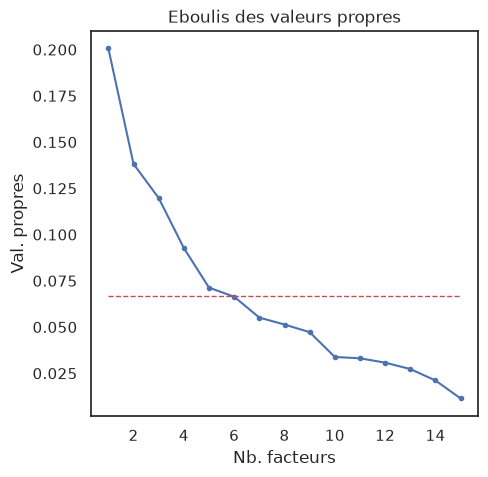

In [442]:
#librairie graphique
import matplotlib.pyplot as plt
#éboulis des v.p.
fix,ax = plt.subplots(figsize=(5,5))
ax.plot(range(1,Hmax+1),acm.eig_[0],".-")
ax.set_xlabel("Nb. facteurs")
ax.set_ylabel("Val. propres")
plt.title("Eboulis des valeurs propres")
#seuil - Règle de Kaiser
ax.plot([1,Hmax],[1/p,1/p],"r--",linewidth=1)
plt.show()

In [443]:
#récupérer les valeurs propres supérieur à (1/p)
lambada = acm.eig_[0][acm.eig_[0]>1/p]
print(lambada)
#appliquer la correction
lambada_prim = ((p/(p-1))*(lambada-1/p))**2
print(lambada_prim)
#faire la somme
S_prim = np.sum(lambada_prim)
print(S_prim)

[0.20059815 0.13817467 0.11973681 0.09270038 0.0712958 ]
[2.05916799e-02 5.86996812e-03 3.23315784e-03 7.78034373e-04
 2.45994271e-05]
0.030497439616409605


In [444]:
#et produire les pourcentages
percent_prim = lambada_prim/S_prim*100
#affichage
print(pd.DataFrame(np.transpose(np.array([lambada_prim,percent_prim,np.cumsum(percent_prim)])),columns=['Val.P','%','Cumul %'],index=range(1,len(lambada)+1)))


      Val.P          %     Cumul %
1  0.020592  67.519372   67.519372
2  0.005870  19.247413   86.766785
3  0.003233  10.601407   97.368193
4  0.000778   2.551147   99.919339
5  0.000025   0.080661  100.000000


In [445]:
#somme corrigée de Greenacre (S’’)
S2nd = p/(p-1)*(np.sum(acm.eig_[0]**2)-(M-p)/(p**2))
print(S2nd)
#pourcentage corrigé Greenacre
percent_2nd = lambada_prim/S2nd

#affichage
print(pd.DataFrame(np.transpose(np.array([lambada_prim,percent_2nd,np.cumsum(percent_2nd)])),columns=['Val.P','%','Cumul %'],index=range(1,len(lambada)+1)))

0.04017038010831944
      Val.P         %   Cumul %
1  0.020592  0.512609  0.512609
2  0.005870  0.146127  0.658735
3  0.003233  0.080486  0.739221
4  0.000778  0.019368  0.758590
5  0.000025  0.000612  0.759202


In [446]:
len(acm.col_coord_[:,:2])

30

In [447]:
#affichage des coordonnées
print(pd.DataFrame(acm.col_coord_[:,:2],index=X.columns,columns=['Coord.F1','Coord.F2']))

                                             Coord.F1  Coord.F2
Aucun logiciel_Non                          -0.378343  0.020798
Aucun logiciel_Oui                           1.422571 -0.078199
Données d'enquête_Non                        0.592310 -0.117917
Données d'enquête_Oui                       -0.526498  0.104815
Données d'entretien_Non                      0.685219 -0.208542
Données d'entretien_Oui                     -0.431782  0.131410
Données du web_Non                           0.187474  0.291648
Données du web_Oui                          -0.874879 -1.361025
Données expérimentales ou d'observation_Non  0.568635 -0.324479
Données expérimentales ou d'observation_Oui -0.522777  0.298311
Données géographiques ou spatiales_Non       0.096738  0.022713
Données géographiques ou spatiales_Oui      -0.725532 -0.170345
Données multimédia_Non                       0.142945  0.266411
Données multimédia_Oui                      -0.630258 -1.174630
Données statistiques_Non                

In [449]:
df_rows = acm.row_topandas()


df_cols = acm.col_topandas()

df_cols[['col_contrib_dim1', 'col_contrib_dim2','col_cos2_dim1',
       'col_cos2_dim2']].sort_values('col_contrib_dim1', ascending=False)
df_dim1_2 = df_cols[['col_contrib_dim1', 'col_contrib_dim2','col_cos2_dim1',
       'col_cos2_dim2']].sort_values('col_contrib_dim1', ascending=False)
df_dim1_2["cum_cos2"] = df_dim1_2.col_cos2_dim1 + df_dim1_2.col_cos2_dim2
df_dim1_2.sort_values('cum_cos2', ascending=False)

,col_contrib_dim1,col_contrib_dim2,col_cos2_dim1,col_cos2_dim2,cum_cos2
Données du web_Données du web_Oui,4.489001,15.771928,0.164017,0.396940,0.560957
Données du web_Données du web_Non,0.961929,3.379699,0.164017,0.396940,0.560957
Aucun logiciel_Aucun logiciel_Oui,14.129378,0.061983,0.538221,0.001626,0.539847
Aucun logiciel_Aucun logiciel_Non,3.757813,0.016485,0.538221,0.001626,0.539847
excel_excel_Non,10.201599,0.521885,0.462388,0.016293,0.478681
excel_excel_Oui,5.165367,0.264246,0.462388,0.016293,0.478681
Métadonnées_Métadonnées_Non,0.527805,3.139738,0.085904,0.351996,0.437900
Métadonnées_Métadonnées_Oui,2.327140,13.843389,0.085904,0.351996,0.437900
Données multimédia_Données multimédia_Non,0.553535,2.791319,0.090092,0.312934,0.403027
Données multimédia_Données multimédia_Oui,2.440586,12.307179,0.090092,0.312934,0.403027


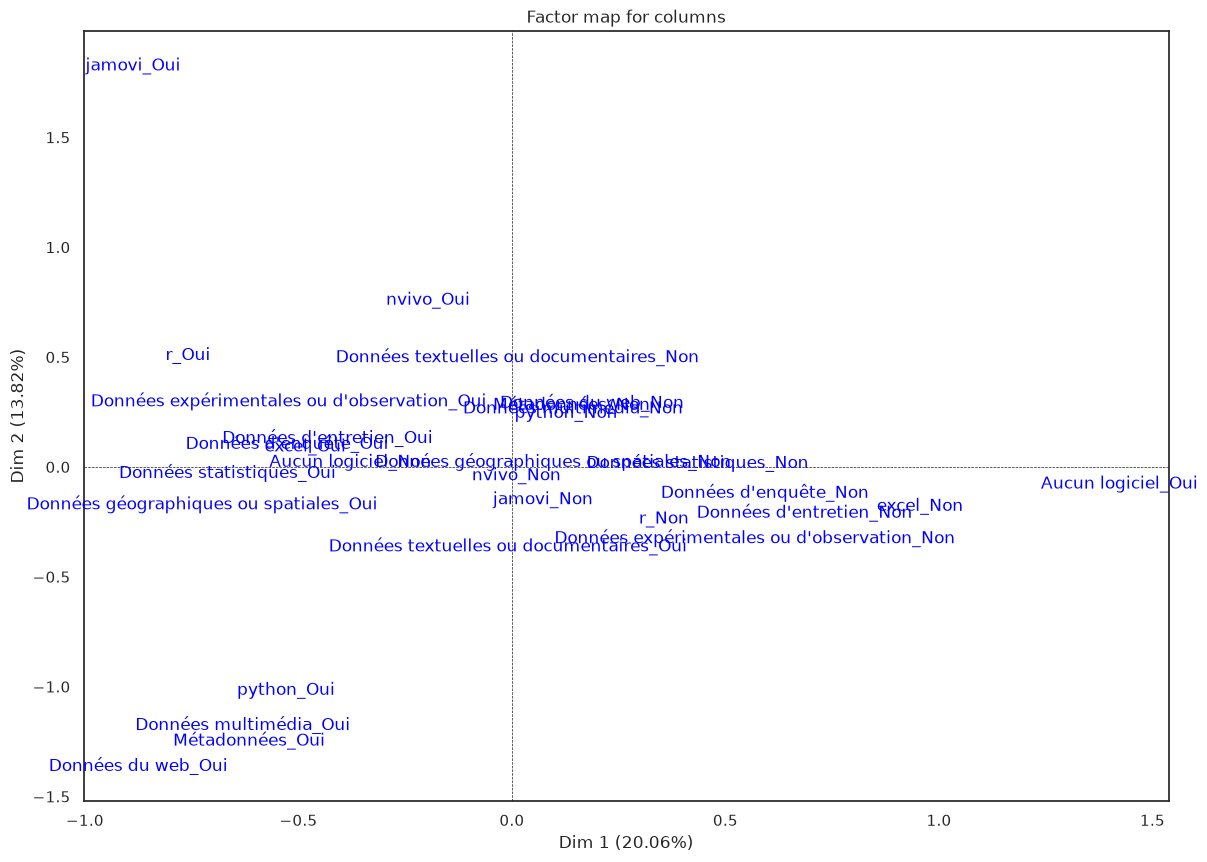

In [450]:


# Mapping simultané des points lignes et colonnes
# Les paramètres de la méthode mapping indiquent que ce sont les axes 1 et 2 qui sont ici représentés
acm.mapping_col(num_x_axis=1, num_y_axis=2, short_labels=True)



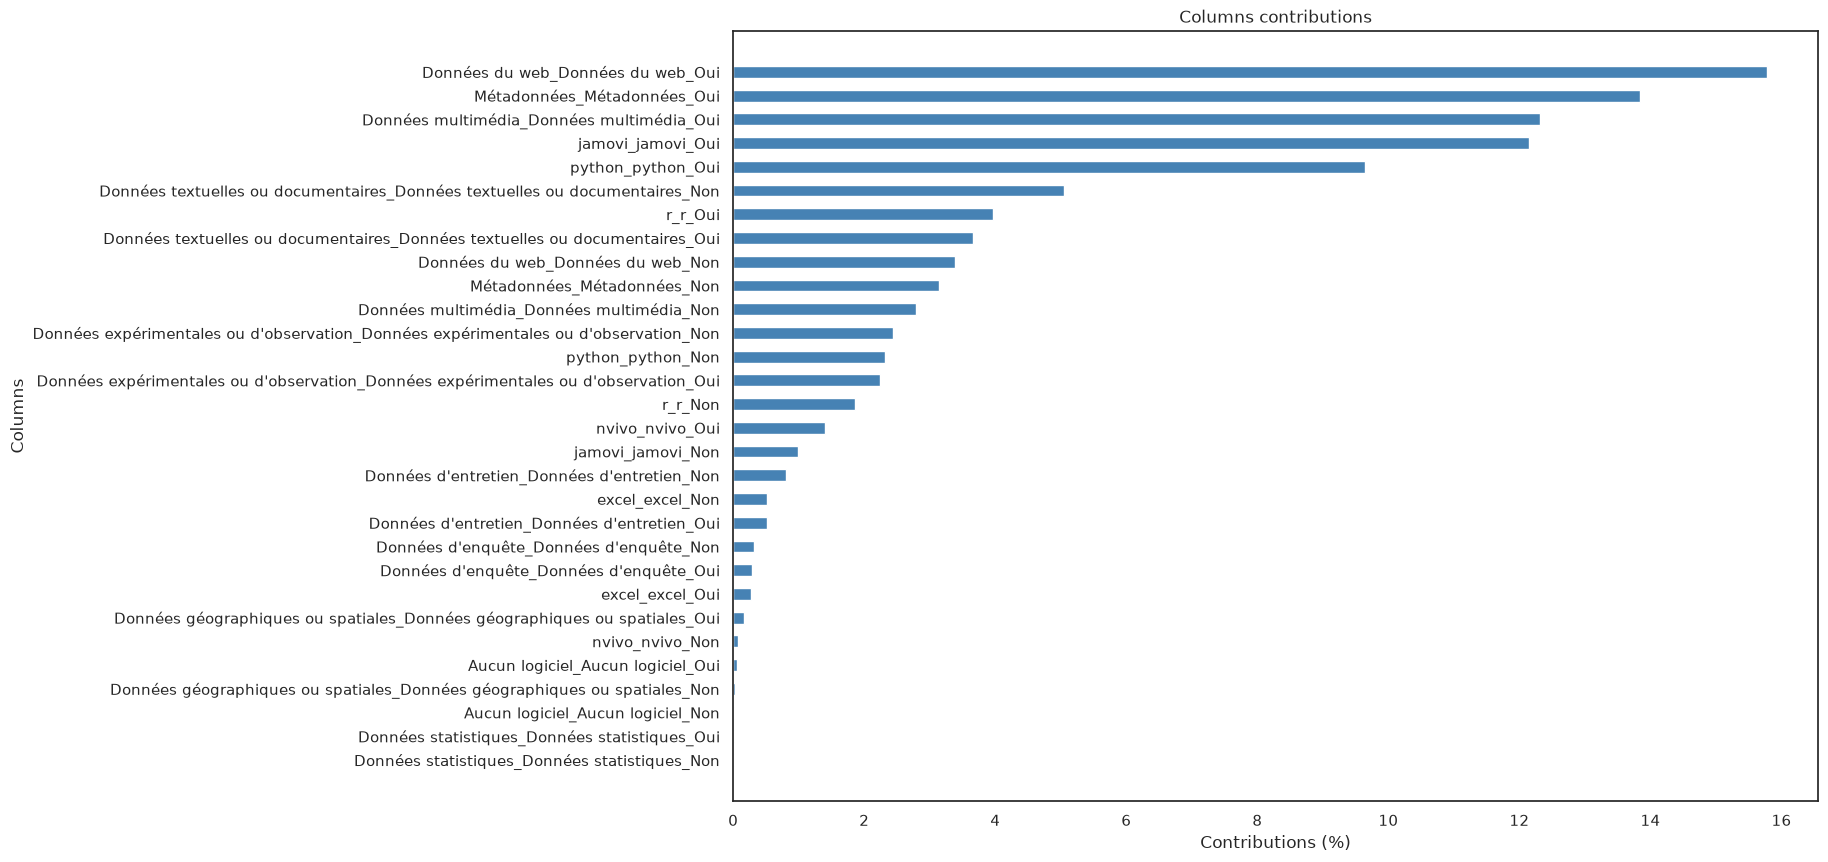

In [452]:
#ou bien graphiquement
acm.plot_col_contrib(num_axis=2, short_labels=False)

In [453]:
#affichage des COS2
print(pd.DataFrame(acm.col_cos2_[:,:2],index=df_cols.index,columns=['Cos2.F1','Cos2.F2']))

                                                     Cos2.F1   Cos2.F2
Aucun logiciel_Aucun logiciel_Non                   0.538221  0.001626
Aucun logiciel_Aucun logiciel_Oui                   0.538221  0.001626
Données d'enquête_Données d'enquête_Non             0.311850  0.012359
Données d'enquête_Données d'enquête_Oui             0.311850  0.012359
Données d'entretien_Données d'entretien_Non         0.295865  0.027405
Données d'entretien_Données d'entretien_Oui         0.295865  0.027405
Données du web_Données du web_Non                   0.164017  0.396940
Données du web_Données du web_Oui                   0.164017  0.396940
Données expérimentales ou d'observation_Données...  0.297269  0.096796
Données expérimentales ou d'observation_Données...  0.297269  0.096796
Données géographiques ou spatiales_Données géog...  0.070186  0.003869
Données géographiques ou spatiales_Données géog...  0.070186  0.003869
Données multimédia_Données multimédia_Non           0.090092  0.312934
Donnée

In [454]:
#affichage des COS2 cumulés
print(pd.DataFrame(np.cumsum(acm.col_cos2_[:,:2],axis=1),index=df_cols.index,columns=['Cos2.F1','Cum(Cos2).F2']))

                                                     Cos2.F1  Cum(Cos2).F2
Aucun logiciel_Aucun logiciel_Non                   0.538221      0.539847
Aucun logiciel_Aucun logiciel_Oui                   0.538221      0.539847
Données d'enquête_Données d'enquête_Non             0.311850      0.324209
Données d'enquête_Données d'enquête_Oui             0.311850      0.324209
Données d'entretien_Données d'entretien_Non         0.295865      0.323270
Données d'entretien_Données d'entretien_Oui         0.295865      0.323270
Données du web_Données du web_Non                   0.164017      0.560957
Données du web_Données du web_Oui                   0.164017      0.560957
Données expérimentales ou d'observation_Données...  0.297269      0.394065
Données expérimentales ou d'observation_Données...  0.297269      0.394065
Données géographiques ou spatiales_Données géog...  0.070186      0.074055
Données géographiques ou spatiales_Données géog...  0.070186      0.074055
Données multimédia_Donnée

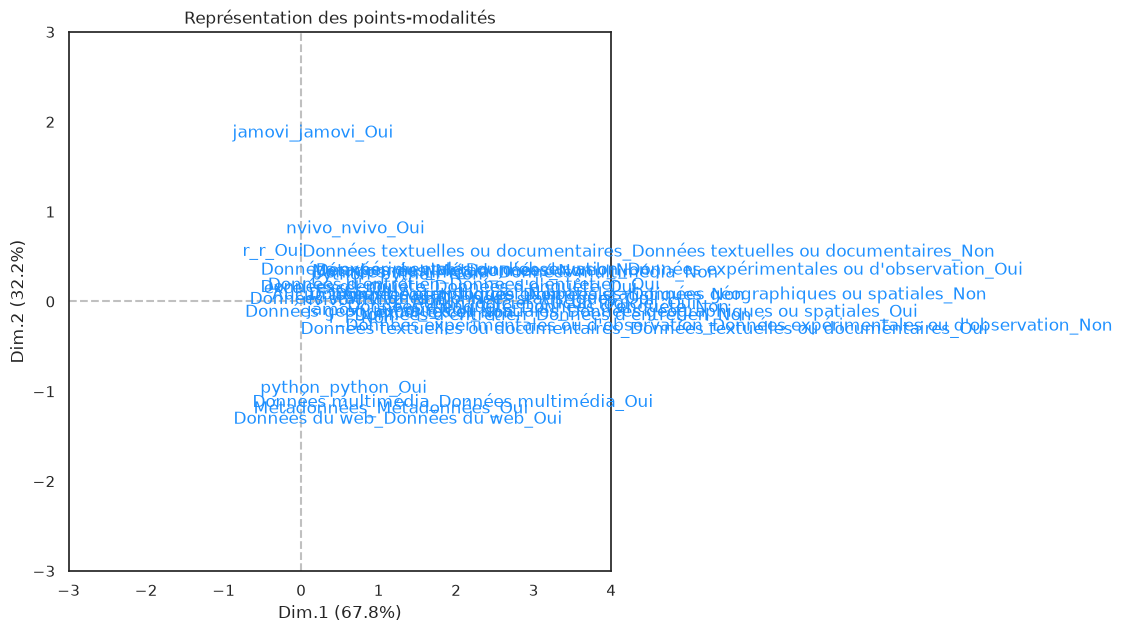

In [455]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(7,7))
ax.axis([-3,+4,-3,+3])
ax.plot([-3,+3],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[-3,+3],color='silver',linestyle='--')
ax.set_xlabel("Dim.1 (67.8%)")
ax.set_ylabel("Dim.2 (32.2%)")
plt.title("Représentation des points-modalités")
for i in range(df_cols.shape[0]):
    ax.text(acm.col_coord_[i,0],acm.col_coord_[i,1],df_cols.index[i],color='dodgerblue')
plt.show()

In [456]:
df_os.columns

Index(['Aucun logiciel', 'Données d'enquête', 'Données d'entretien',
       'Données du web', 'Données expérimentales ou d'observation',
       'Données géographiques ou spatiales', 'Données multimédia',
       'Données statistiques', 'Données textuelles ou documentaires',
       'Métadonnées', 'excel', 'jamovi', 'nvivo', 'python', 'r',
       'label_recherche_1'],
      dtype='object')

In [457]:
contrib12

,0,1
Aucun logiciel_Non,8.698727,0.024690
Aucun logiciel_Oui,32.359266,0.091847
excel_Non,22.817576,5.291758
excel_Oui,11.264373,2.612387
jamovi_Non,0.569827,0.069867
jamovi_Oui,6.901235,0.846163
nvivo_Non,0.003866,2.059096
nvivo_Oui,0.072162,38.436467
python_Non,0.328312,6.971354
python_Oui,1.356071,28.794723


In [458]:
df_os

,Aucun logiciel,Données d'enquête,Données d'entretien,Données du web,Données expérimentales ou d'observation,Données géographiques ou spatiales,Données multimédia,Données statistiques,Données textuelles ou documentaires,Métadonnées,excel,jamovi,nvivo,python,r,label_recherche_1
q45_clé,,,,,,,,,,,,,,,,
2DRU-P3AV,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Oui,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Non,Données textuelles ou documentaires_Oui,Métadonnées_Oui,excel_Oui,jamovi_Non,nvivo_Non,python_Oui,r_Non,Psychologie
2JQN-P9PA,Aucun logiciel_Non,Données d'enquête_Non,Données d'entretien_Non,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,Données textuelles ou documentaires_Non,Métadonnées_Non,excel_Oui,jamovi_Non,nvivo_Non,python_Non,r_Oui,Psychologie
2QNC-8AAQ,Aucun logiciel_Oui,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Non,jamovi_Non,nvivo_Non,python_Non,r_Non,"Individus, normes, sociétés"
2Y89-7BR9,Aucun logiciel_Non,Données d'enquête_Non,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Oui,jamovi_Non,nvivo_Non,python_Non,r_Non,Psychologie
32TW-JLY5,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Non,Données du web_Oui,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Oui,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Oui,jamovi_Non,nvivo_Non,python_Oui,r_Non,Sciences informatiques
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Oui,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Oui,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Oui,jamovi_Non,nvivo_Non,python_Non,r_Non,Histoires de l'art et des sciences
YTMC-B4DP,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Oui,Données textuelles ou documentaires_Non,Métadonnées_Non,excel_Oui,jamovi_Oui,nvivo_Non,python_Non,r_Oui,Psychologie sociale
ZB5S-ABHN,Aucun logiciel_Non,Données d'enquête_Non,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Oui,Données textuelles ou documentaires_Non,Métadonnées_Non,excel_Oui,jamovi_Non,nvivo_Non,python_Non,r_Oui,Psychologie


In [459]:
#contrib12.loc[np.unique(df_os.iloc[:,1])][0]
contrib12
df_cols.index

Index(['Aucun logiciel_Aucun logiciel_Non',
       'Aucun logiciel_Aucun logiciel_Oui',
       'Données d'enquête_Données d'enquête_Non',
       'Données d'enquête_Données d'enquête_Oui',
       'Données d'entretien_Données d'entretien_Non',
       'Données d'entretien_Données d'entretien_Oui',
       'Données du web_Données du web_Non',
       'Données du web_Données du web_Oui',
       'Données expérimentales ou d'observation_Données expérimentales ou d'observation_Non',
       'Données expérimentales ou d'observation_Données expérimentales ou d'observation_Oui',
       'Données géographiques ou spatiales_Données géographiques ou spatiales_Non',
       'Données géographiques ou spatiales_Données géographiques ou spatiales_Oui',
       'Données multimédia_Données multimédia_Non',
       'Données multimédia_Données multimédia_Oui',
       'Données statistiques_Données statistiques_Non',
       'Données statistiques_Données statistiques_Oui',
       'Données textuelles ou documentaires_

In [460]:
#récupération des contribution sous une forme exploitable - 2 facteurs
contrib12 = pd.DataFrame(acm.col_contrib_[:,:2],index=X.columns)
print(contrib12)

#**calcul des carrés des rapports de corrélation par variable sur les 2 facteurs**
#structure pour les eta2
#structure pour les eta2
cols=len(table.columns)
eta2 = np.zeros((cols,2))
#pour chaque facteur
for h in range(2):
    #pour chaque variable
    for j in range(cols):
        eta2[j,h] = (p*acm.eig_[0][h]*np.sum(contrib12.loc[np.unique(table.iloc[:,j])][h]))/100
            #affichage

print(pd.DataFrame(eta2,index=table.columns[:],columns=['F1','F2']))



                                                     0          1
Aucun logiciel_Non                            3.757813   0.016485
Aucun logiciel_Oui                           14.129378   0.061983
Données d'enquête_Non                         5.486821   0.315698
Données d'enquête_Oui                         4.877174   0.280620
Données d'entretien_Non                       6.031863   0.811111
Données d'entretien_Oui                       3.800900   0.511111
Données du web_Non                            0.961929   3.379699
Données du web_Oui                            4.489001  15.771928
Données expérimentales ou d'observation_Non   5.147268   2.433216
Données expérimentales ou d'observation_Oui   4.732166   2.236989
Données géographiques ou spatiales_Non        0.274420   0.021961
Données géographiques ou spatiales_Oui        2.058148   0.164710
Données multimédia_Non                        0.553535   2.791319
Données multimédia_Oui                        2.440586  12.307179
Données st

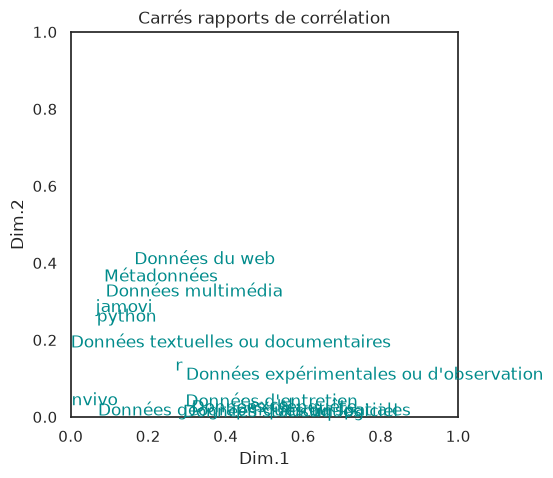

In [461]:
fix,ax = plt.subplots(figsize=(5,5))
ax.axis([0,+1,0,+1])
ax.set_xlabel("Dim.1")
ax.set_ylabel("Dim.2")
plt.title("Carrés rapports de corrélation")
for i in range(cols):
    ax.text(eta2[i,0],eta2[i,1],df_os.columns[i],color='darkcyan')
plt.show()

In [462]:
df_coord = pd.DataFrame(acm.row_coord_[:,:2],index=X.index,columns=['F1','F2'])
df_coord['champ'] = Dillustratives.label_recherche_1
print(df_coord)

                 F1        F2                                      champ
q45_clé                                                                 
2DRU-P3AV -0.600128 -0.878919                                Psychologie
2JQN-P9PA  0.053310  0.363195                                Psychologie
2QNC-8AAQ  0.527873 -0.001815                Individus, normes, sociétés
2Y89-7BR9  0.212077  0.024456                                Psychologie
32TW-JLY5 -0.485338 -0.673947                     Sciences informatiques
...             ...       ...                                        ...
YL4Q-KQAK -0.276445 -0.240160         Histoires de l'art et des sciences
YTMC-B4DP -0.701299  0.551531                        Psychologie sociale
ZB5S-ABHN -0.276813  0.416004                                Psychologie
ZBFK-V8BA  0.059609 -0.327198                     Sciences informatiques
ZGPH-2FPH -0.886380 -0.921704  Etudes sociales des arts et de la culture

[119 rows x 3 columns]


In [463]:
#calcul des moyennes conditionnelles
GBar = pd.pivot_table(df_coord,values=['F1','F2'],index="champ",aggfunc='mean')
print(GBar)

                                                 F1        F2
champ                                                        
Etudes littéraires                         0.579645 -0.038444
Etudes sociales des arts et de la culture  0.018971 -0.251983
Histoires de l'art et des sciences        -0.033581 -0.001660
Individus, normes, sociétés               -0.054166 -0.042331
Psychologie                               -0.173990  0.213117
Psychologie sociale                       -0.401446  0.634603
Recherche et création                      0.426697  0.009411
Sciences info. com.                       -0.046445 -0.035972
Sciences informatiques                     0.114841 -0.348874
Sciences économiques                      -0.004336 -0.019593
Sociétés, espaces et envrionnements       -0.363364  0.133731


In [464]:
#coordonnées factorielles des modalités - Solution 1
Gv1 = GBar.values/np.sqrt(acm.eig_[0][:2])
Gv1 = pd.DataFrame(Gv1,index=GBar.index,columns=GBar.columns)
print(Gv1)

                                                 F1        F2
champ                                                        
Etudes littéraires                         1.294192 -0.103423
Etudes sociales des arts et de la culture  0.042358 -0.677885
Histoires de l'art et des sciences        -0.074976 -0.004465
Individus, normes, sociétés               -0.120937 -0.113879
Psychologie                               -0.388472  0.573328
Psychologie sociale                       -0.896322  1.707213
Recherche et création                      0.952701  0.025317
Sciences info. com.                       -0.103698 -0.096772
Sciences informatiques                     0.256409 -0.938543
Sciences économiques                      -0.009680 -0.052709
Sociétés, espaces et envrionnements       -0.811294  0.359765


/tmp/ipykernel_2651/171588202.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.text(Gv1.loc[i][0],Gv1.loc[i][1],i,color='red')


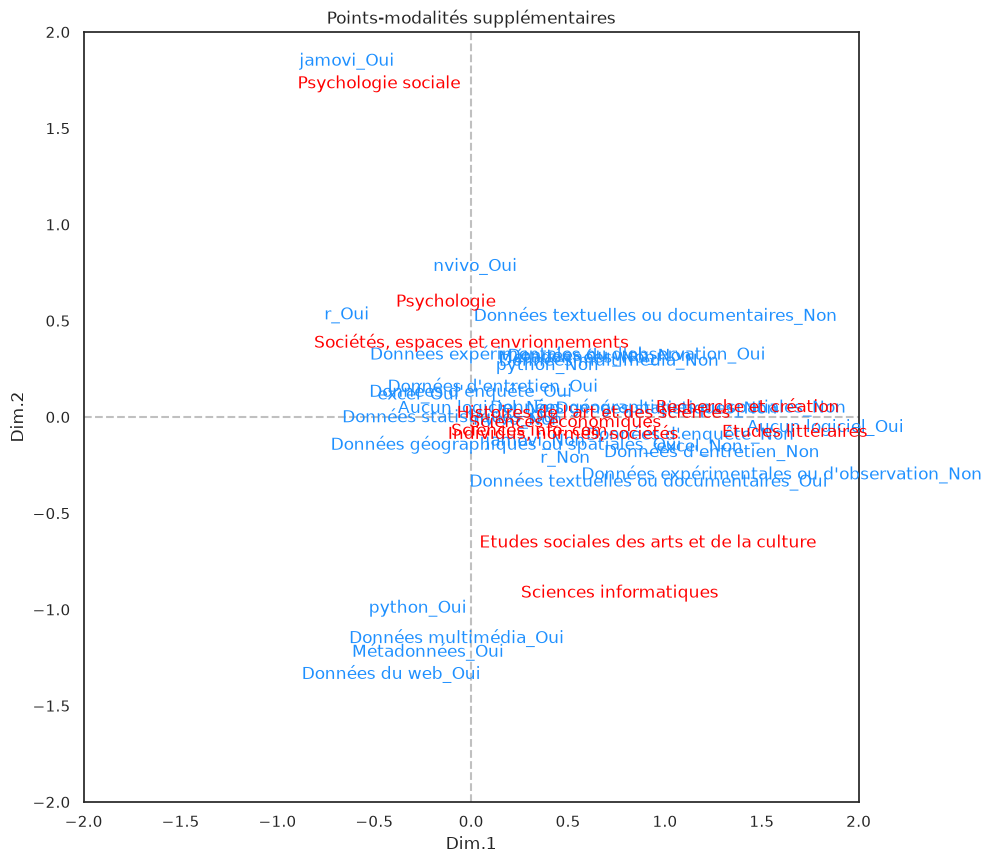

In [465]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(10,10))
ax.axis([-2,+2,-2,+2])
ax.plot([-2,+2],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[-2,+2],color='silver',linestyle='--')
ax.set_xlabel("Dim.1")
ax.set_ylabel("Dim.2")
plt.title("Points-modalités supplémentaires")
#modalités actives
for i in range(X.shape[1]):
    ax.text(acm.col_coord_[i,0],acm.col_coord_[i,1],X.columns[i],color='dodgerblue')
#modalités illustratives de la variable "fonction"
for i in Gv1.index:
    ax.text(Gv1.loc[i][0],Gv1.loc[i][1],i,color='red')
plt.show()

In [477]:
print(df0.auto_lab_research_cluster.value_counts().to_markdown())

| auto_lab_research_cluster                                                                                                                                       |   count |
|:----------------------------------------------------------------------------------------------------------------------------------------------------------------|--------:|
| ["SH4 L'esprit humain et sa complexité", 'SH8 Études des cultures et des arts', "SH6 L'étude du passé humain"]                                                  |      18 |
| ["SH4 L'esprit humain et sa complexité", 'LS5 Neurosciences et troubles du système nerveux', 'LS4 Physiologie de la santé, de la maladie et du vieillissement'] |      17 |
| ['SH2 Institutions, gouvernance et systèmes juridiques', 'SH1 Individus, marchés et organisations', 'SH7 Mobilité humaine, environnement et espace']            |      16 |
| ['SH8 Études des cultures et des arts', "SH6 L'étude du passé humain", 'SH1 Individus, marchés et organisations']               